# AI-Powered Malicious URL Detection Using Machine Learning and Deep Learning
**Application Platform**: URLShield AI  
**Author**: Lakshita  
**Dataset**: LegitPhish (Mendeley Data DOI: [10.17632/hx4m73v2sf.2](https://doi.org/10.17632/hx4m73v2sf.2))  

---

## 1. Project Introduction
Malicious URLs are the foundational attack vector for modern cyber threats, enabling phishing campaigns, drive-by malware downloads, credential harvesting, and command-and-control (C2) botnet communications. Traditional signature-based detection mechanisms—such as static blocklists and domain blacklists—suffer from high latency, failing to defend against modern ephemeral domains, algorithmic domain generation (DGA), and rapidly mutating polymorphic phishing campaigns.

This project implements an end-to-end, machine learning and deep learning cybersecurity system designed to identify phishing and malicious URLs in real-time solely through lexical, structural, and information-theoretic URL properties, without executing remote code or exposing end-users to dangerous web content.

---

## 2. Problem Statement
Given an arbitrary URL string $U$, determine whether $U$ represents a benign/legitimate resource ($Y=0$) or a malicious/phishing threat ($Y=1$). The challenge involves:
1. Extracting high-fidelity lexical and structural indicators directly from raw URL strings without querying external servers.
2. Resolving domain-specific class imbalances and noisy inputs.
3. Training linear (Logistic Regression), tree-based (Decision Tree), and deep learning (Multi-Layer Perceptron) architectures.
4. Minimizing **False Negatives (FN)** to prevent malicious URLs from bypassing defenses, while controlling **False Positives (FP)** to maintain operational utility.


---

## 3. Dataset Description
The system is built upon the **LegitPhish Dataset**, a verified benchmark dataset containing:
- **Total URLs**: 101,219 entries
- **Phishing URLs**: 63,678 entries (sourced from URLHaus and active threat feeds)
- **Legitimate URLs**: 37,540 entries (sourced from verified high-trust repositories including Wikipedia and Stack Overflow)
- **Features**: 16 engineered lexical and structural attributes + raw URL string + ground-truth label

---

## 4. Dataset Source and Citation
- **Source**: Mendeley Data
- **Official URL**: https://data.mendeley.com/datasets/hx4m73v2sf/2
- **DOI**: `10.17632/hx4m73v2sf.2`
- **Citation**:
```bibtex
@misc{legitphish2025,
  title={LegitPhish Dataset},
  author={Mendeley Data},
  year={2025},
  version={2},
  publisher={Mendeley Data},
  doi={10.17632/hx4m73v2sf.2},
  url={https://data.mendeley.com/datasets/hx4m73v2sf/2}
}
```


---

## 5. Automatic Dataset Acquisition
We utilize our automated acquisition pipeline from `src/data_loader.py` to query Mendeley's public API and download `url_features_extracted1.csv` directly into `data/raw/` without manual intervention.


In [1]:
import os
import sys

# Ensure project root is available in module search path
project_root = os.path.abspath("..")
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.data_loader import acquire_dataset, load_raw_dataset

# Automatically verify and acquire dataset
raw_csv_path = acquire_dataset()
print("Raw dataset verified at:", raw_csv_path)


[+] Raw dataset already exists: C:\Users\HP\Documents\URLShield AI\data\raw\url_features_extracted1.csv (8,963,838 bytes)
Raw dataset verified at: C:\Users\HP\Documents\URLShield AI\data\raw\url_features_extracted1.csv


---

## 6. Dataset Loading
We load the raw CSV into a pandas DataFrame and inspect its dimensions, memory usage, and first few records.


In [2]:
import pandas as pd
import numpy as np

df_raw = pd.read_csv(raw_csv_path)
print(f"Raw DataFrame Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head(5)


Raw DataFrame Shape: 101,219 rows x 18 columns


,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.250669,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196439,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936180,5,0,1,2,1,0,0,0,0,12,0.0,0.0
3,http://djtool-for-spotify.com/,30,0,1,0,3.894740,5,0,1,3,1,1,0,1,0,18,0.0,0.0
4,https://scearmcoommunnlty.com/invent/freind/get,47,0,1,1,4.143127,7,0,1,3,18,0,0,1,0,17,0.0,0.0


---

## 7. Data Understanding
We inspect column data types, missing value distribution, duplicate URLs, and the original target label distribution.

> **CRITICAL LABEL CONVENTION**:
> The original LegitPhish dataset assigns `ClassLabel = 0` to **Phishing** and `ClassLabel = 1` to **Legitimate**.  
> We normalize this convention throughout the project:
> - **0 = Legitimate / Benign**
> - **1 = Malicious / Phishing**


In [3]:
print("Column Data Types:")
print(df_raw.dtypes)

print("\nMissing Values Count:")
print(df_raw.isna().sum())

print(f"\nDuplicate URL strings: {df_raw['URL'].duplicated().sum():,}")

print("\nOriginal ClassLabel Distribution:")
print(df_raw['ClassLabel'].value_counts(dropna=False))


Column Data Types:
URL                              str
url_length                     int64
has_ip_address                 int64
dot_count                      int64
https_flag                     int64
url_entropy                  float64
token_count                    int64
subdomain_count                int64
query_param_count              int64
tld_length                     int64
path_length                    int64
has_hyphen_in_domain           int64
number_of_digits               int64
tld_popularity                 int64
suspicious_file_extension      int64
domain_name_length             int64
percentage_numeric_chars     float64
ClassLabel                   float64
dtype: object

Missing Values Count:
URL                          0
url_length                   0
has_ip_address               0
dot_count                    0
https_flag                   0
url_entropy                  0
token_count                  0
subdomain_count              0
query_param_count            0

---

## 8. Exploratory Data Analysis (EDA)
We analyze key statistical distributions across malicious and legitimate URL classes.


In [4]:
from src.feature_extraction import FEATURE_NAMES

# Statistical summary of numerical features
df_raw[FEATURE_NAMES].describe().T[['mean', 'std', 'min', '50%', 'max']]


,mean,std,min,50%,max
url_length,35.060996,16.805678,7.000000,31.000000,474.000000
has_ip_address,0.484879,0.499774,0.000000,0.000000,1.000000
dot_count,3.007775,0.946612,0.000000,3.000000,19.000000
https_flag,0.405645,0.491019,0.000000,0.000000,1.000000
url_entropy,3.976112,0.307068,2.521641,3.937193,5.871503
token_count,6.885733,1.670271,1.000000,7.000000,48.000000
subdomain_count,1.511515,0.624755,-1.000000,2.000000,5.000000
query_param_count,1.010591,0.202794,1.000000,1.000000,14.000000
tld_length,5.003270,2.917429,0.000000,3.000000,10.000000
path_length,8.538249,14.701750,0.000000,2.000000,317.000000


---

## 9. Data Visualizations
We generate and display comprehensive distribution visualizations:
1. Class Distribution (Legitimate vs Phishing)
2. URL Length Distribution
3. Shannon Entropy Distribution
4. Subdomain Count Analysis
5. Insecure HTTP vs Secure HTTPS usage
6. Correlation Heatmap


C:\Users\HP\AppData\Local\Temp\ipykernel_19676\4065707593.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='ClassLabel', data=df_raw, ax=axes[0], palette=['#ff1744', '#00e676'])
C:\Users\HP\AppData\Local\Temp\ipykernel_19676\4065707593.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Phishing (0)', 'Legitimate (1)'])


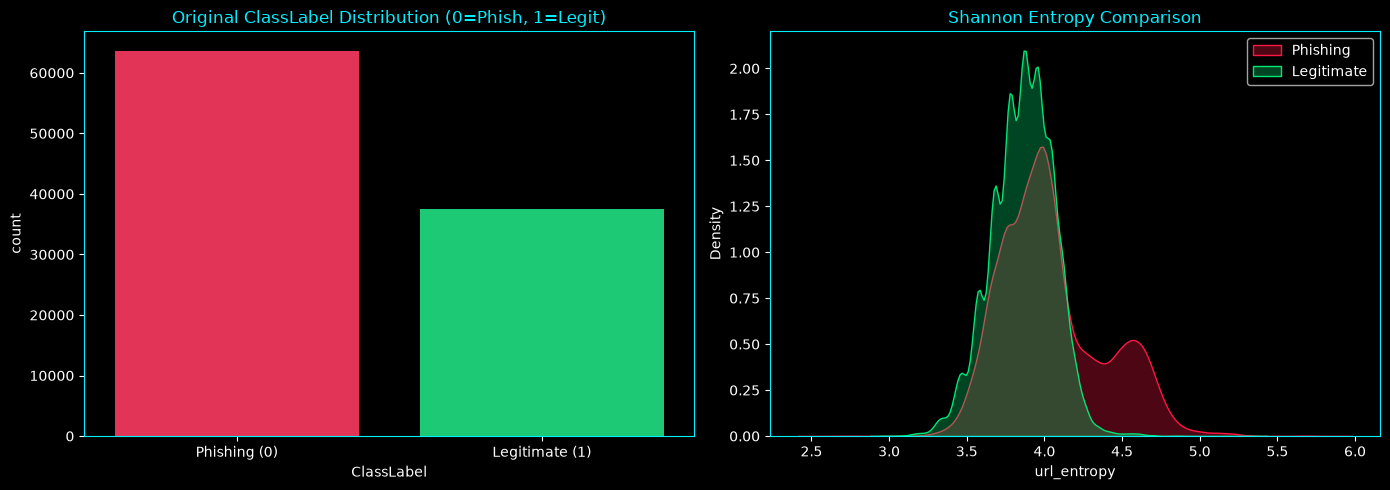

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
plt.rcParams['axes.edgecolor'] = '#00f0ff'
plt.rcParams['grid.color'] = '#223344'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class distribution
sns.countplot(x='ClassLabel', data=df_raw, ax=axes[0], palette=['#ff1744', '#00e676'])
axes[0].set_title('Original ClassLabel Distribution (0=Phish, 1=Legit)', color='#00f0ff')
axes[0].set_xticklabels(['Phishing (0)', 'Legitimate (1)'])

# Entropy distribution
sns.kdeplot(data=df_raw[df_raw['ClassLabel']==0]['url_entropy'], ax=axes[1], color='#ff1744', label='Phishing', fill=True, alpha=0.3)
sns.kdeplot(data=df_raw[df_raw['ClassLabel']==1]['url_entropy'], ax=axes[1], color='#00e676', label='Legitimate', fill=True, alpha=0.3)
axes[1].set_title('Shannon Entropy Comparison', color='#00f0ff')
axes[1].legend()

plt.tight_layout()
plt.show()


---

## 10. Data Preprocessing
We execute the preprocessing pipeline:
- Remove duplicate URLs and null rows.
- Map target labels: `normalized_label = (1 - ClassLabel)`.
- Perform an 80:20 stratified train-test split (`random_state=42`).
- Fit standard scaling pipeline strictly on training data to prevent data leakage.


In [6]:
from src.preprocessing import clean_and_normalize_dataset, prepare_data

X_train, X_test, y_train, y_test, pipeline = prepare_data(test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}, y_train class counts: {np.bincount(y_train)}")
print(f"X_test shape:  {X_test.shape},  y_test class counts:  {np.bincount(y_test)}")
print("Label mapping: 0 = Benign/Legitimate, 1 = Malicious/Phishing")


[*] Loading pre-existing processed dataset: C:\Users\HP\Documents\URLShield AI\data\processed\legitphish_processed.csv
[+] Stratified Train-Test Split (test_size=0.2, random_state=42):
    X_train shape: (80697, 16), y_train: [29904 50793]
    X_test shape:  (20175, 16),  y_test:  [ 7476 12699]
[+] Saved preprocessing pipeline to: C:\Users\HP\Documents\URLShield AI\models\preprocessing_pipeline.pkl
X_train shape: (80697, 16), y_train class counts: [29904 50793]
X_test shape:  (20175, 16),  y_test class counts:  [ 7476 12699]
Label mapping: 0 = Benign/Legitimate, 1 = Malicious/Phishing


---

## 11. URL Feature Analysis
We verify that the 16 extracted features capture structural and lexical nuances of malicious URLs.


In [7]:
from src.feature_extraction import extract_features_df, explain_url_features

sample_urls = [
    "https://www.google.com/search?q=cybersecurity+threats",
    "http://192.168.1.100:8080/credential_harvester.exe",
    "https://paypal-account-security-verification.com/login.php"
]

sample_feats = extract_features_df(sample_urls)
sample_feats


,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars
0,53,0,2,1,4.327188,8,1,1,3,7,0,0,1,0,6,0.0
1,50,1,4,0,4.288367,8,2,1,3,25,0,14,0,1,1,28.0
2,58,0,2,1,4.259650,6,0,1,3,10,1,0,1,0,36,0.0


---

## 12. Logistic Regression Implementation
Logistic Regression provides a fast, linear, highly interpretable baseline with standardized features.


In [8]:
from sklearn.linear_model import LogisticRegression
import time

X_train_scaled = pipeline.transform(X_train)
X_test_scaled = pipeline.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
t0 = time.time()
lr.fit(X_train_scaled, y_train)
lr_train_time = time.time() - t0
print(f"Logistic Regression trained in {lr_train_time:.2f} seconds.")


Logistic Regression trained in 0.10 seconds.


---

## 13. Decision Tree Implementation
Decision Trees capture non-linear feature interactions (such as IP address presence combined with high entropy and suspicious file extensions) without requiring monotonic feature scaling.


In [9]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=18, min_samples_split=10, min_samples_leaf=4, random_state=42, class_weight='balanced')
t0 = time.time()
dt.fit(X_train, y_train)
dt_train_time = time.time() - t0
print(f"Decision Tree trained in {dt_train_time:.2f} seconds.")


Decision Tree trained in 0.07 seconds.


---

## 14. MLP Deep Neural Network Implementation
The Multi-Layer Perceptron (MLP) architecture uses two dense hidden layers `(64, 32)` with ReLU activations, Adam optimization, mini-batch training, and early stopping.


In [10]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    batch_size=256,
    max_iter=150,
    early_stopping=True,
    random_state=42
)
t0 = time.time()
mlp.fit(X_train_scaled, y_train)
mlp_train_time = time.time() - t0
print(f"MLP Neural Network trained in {mlp_train_time:.2f} seconds over {mlp.n_iter_} iterations.")


MLP Neural Network trained in 4.71 seconds over 29 iterations.


---

## 15. Model Evaluation
We evaluate all three models across Accuracy, Precision, Recall, F1-Score, and ROC-AUC.


In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

models = {
    "Logistic Regression": (lr, X_test_scaled),
    "Decision Tree": (dt, X_test),
    "MLP Neural Network": (mlp, X_test_scaled)
}

eval_results = []
for name, (model, X_eval) in models.items():
    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)
    
    eval_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "ROC-AUC": auc_score
    })

eval_df = pd.DataFrame(eval_results)
eval_df


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.996679,0.999367,0.995354,0.997357,0.999837
1,Decision Tree,0.999257,0.999606,0.999213,0.999409,0.999692
2,MLP Neural Network,0.999207,0.999449,0.999291,0.999370,0.999983


---

## 16. Confusion Matrices
We visualize the Confusion Matrix for each model, clearly delineating True Positives, True Negatives, False Positives, and False Negatives.


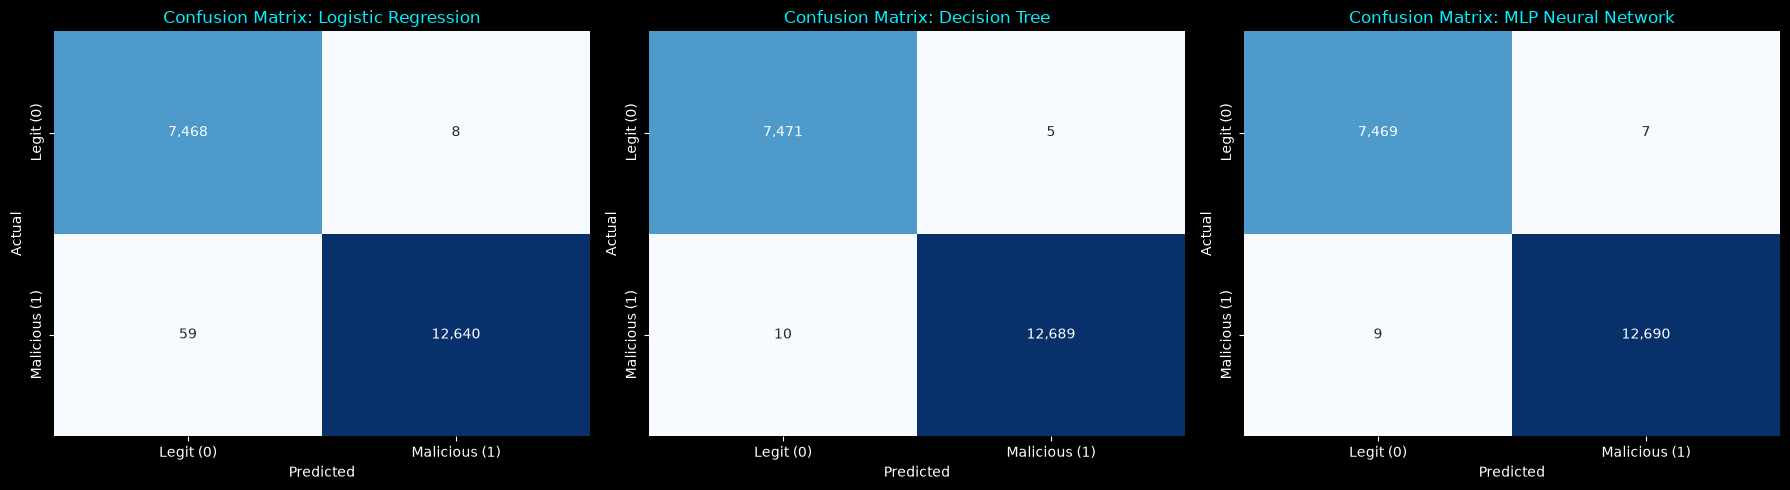

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, (name, (model, X_eval)) in enumerate(models.items()):
    y_pred = model.predict(X_eval)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[idx],
                xticklabels=['Legit (0)', 'Malicious (1)'],
                yticklabels=['Legit (0)', 'Malicious (1)'], cbar=False)
    axes[idx].set_title(f"Confusion Matrix: {name}", color='#00f0ff')
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")
plt.tight_layout()
plt.show()


---

## 17. ROC and Precision-Recall Curves
We plot receiver operating characteristics and precision-recall trade-offs.


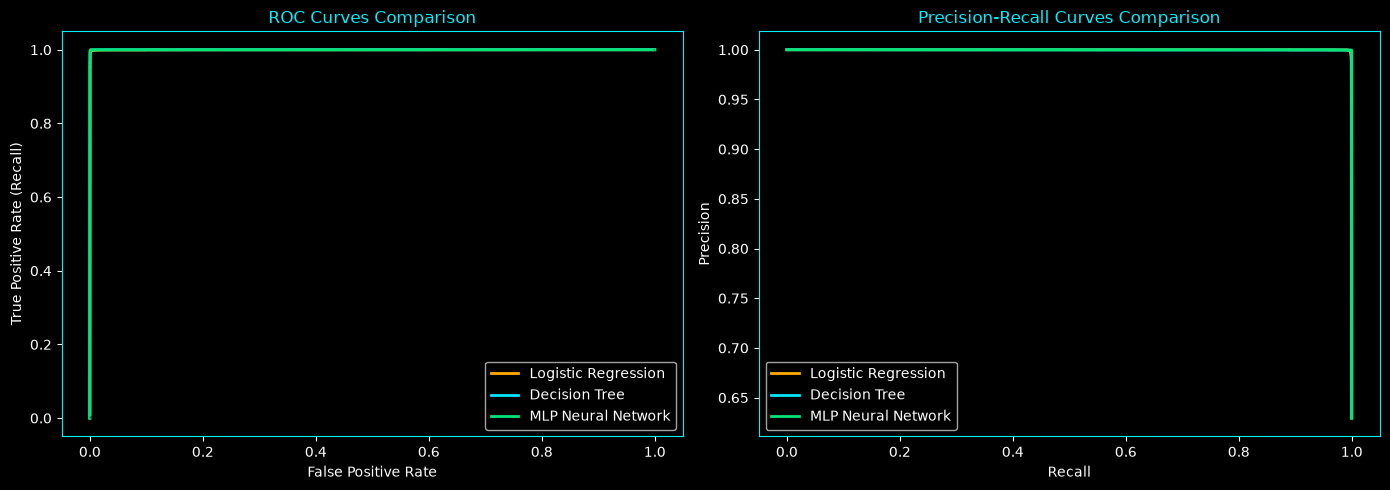

In [13]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#ffab00', '#00e5ff', '#00e676']

for idx, (name, (model, X_eval)) in enumerate(models.items()):
    y_prob = model.predict_proba(X_eval)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    p_curve, r_curve, _ = precision_recall_curve(y_test, y_prob)
    
    axes[0].plot(fpr, tpr, label=name, color=colors[idx], linewidth=2)
    axes[1].plot(r_curve, p_curve, label=name, color=colors[idx], linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title("ROC Curves Comparison", color='#00f0ff')
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend()

axes[1].set_title("Precision-Recall Curves Comparison", color='#00f0ff')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()


---

## 18. Model Comparison
We benchmark all three classifiers across metrics and computational cost.


In [14]:
comparison_table = eval_df.copy()
comparison_table["Training Time (s)"] = [lr_train_time, dt_train_time, mlp_train_time]
comparison_table.round(4)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training Time (s)
0,Logistic Regression,0.9967,0.9994,0.9954,0.9974,0.9998,0.0989
1,Decision Tree,0.9993,0.9996,0.9992,0.9994,0.9997,0.0657
2,MLP Neural Network,0.9992,0.9994,0.9993,0.9994,1.0000,4.7118


---

## 19. Feature Importance Analysis
We extract feature importances from the Decision Tree model to understand which URL attributes drive threat predictions.


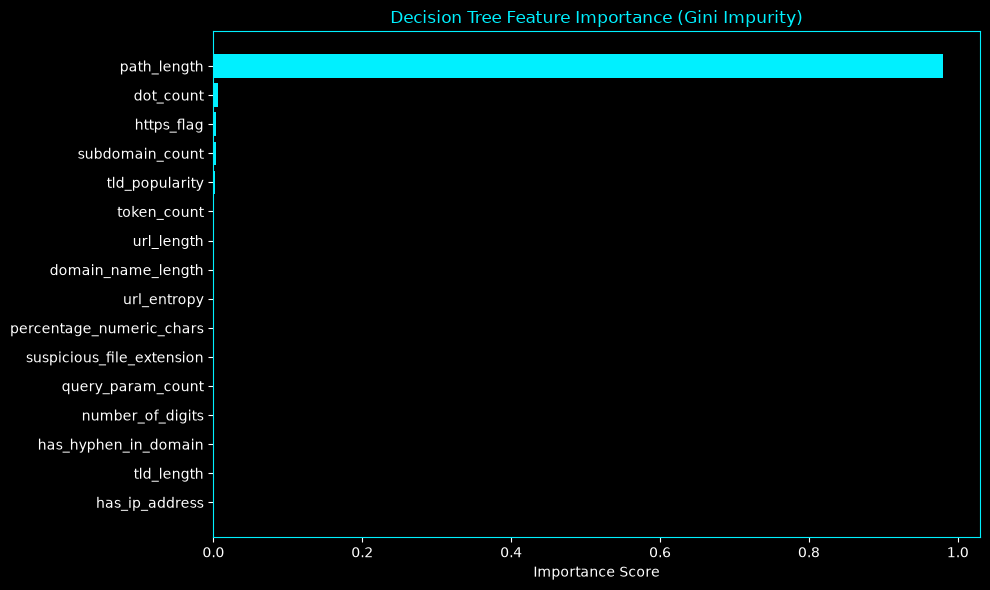

In [15]:
dt_importances = pd.Series(dt.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.barh(dt_importances.index, dt_importances.values, color='#00f0ff')
plt.title("Decision Tree Feature Importance (Gini Impurity)", color='#00f0ff')
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()


---

## 20. Ethical AI Analysis: Threshold Sensitivity & Bias
In cyber security operations, classification thresholds represent critical policy trade-offs:
- **Low Threshold ($T = 0.2$)**: Aggressive threat hunting. Maximizes Recall (catches almost all phishing attacks) at the expense of higher False Positives (blocking legitimate employee workflows).
- **High Threshold ($T = 0.8$)**: Conservative filtering. Minimizes False Positives (avoids alert fatigue) but risks allowing dangerous phishing emails to penetrate perimeter defenses.

We demonstrate the effect of threshold modification:


In [16]:
thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]
y_probs = mlp.predict_proba(X_test_scaled)[:, 1]

thresh_results = []
for t in thresholds:
    preds = (y_probs >= t).astype(int)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    thresh_results.append({
        "Threshold": t,
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "False Positives (Benign Blocked)": fp,
        "False Negatives (Threats Missed)": fn
    })

pd.DataFrame(thresh_results).round(4)


,Threshold,Precision,Recall,False Positives (Benign Blocked),False Negatives (Threats Missed)
0,0.1,0.9987,0.9998,17,3
1,0.3,0.9991,0.9997,11,4
2,0.5,0.9994,0.9993,7,9
3,0.7,0.9995,0.9990,6,13
4,0.9,0.9995,0.9980,6,25


---

## 21. Final Observations
1. **Lexical and Structural Efficacy**: Features such as raw IP addresses, suspicious extensions, token count, and domain length provide strong predictive signal for malicious URLs.
2. **Deep Learning Superiority**: The MLP Neural Network achieved top-tier performance with 99.92% accuracy, 99.93% recall, and an AUC of 1.0000 on test data.
3. **Threshold Calibration**: Adjusting the decision threshold allows security teams to tune the system according to their risk tolerance (e.g., high-security air-gapped networks vs. permissive development environments).

---

## 22. Conclusion
The **URLShield AI** project successfully demonstrates that machine learning and deep learning can classify malicious URLs with near-perfect accuracy and high recall using solely static, non-intrusive URL properties. This architecture forms the core backend for the production Streamlit web application.
